# CO₂ emissions, 1950–2024

In this notebook I try to understand how global CO₂ emissions have evolved, which countries emit the most, and how Europe, Spain and Tunisia compare.

Data: [Our World in Data – CO₂ and Greenhouse Gas Emissions](https://github.com/owid/co2-data) (CC BY 4.0). Emissions are fossil-fuel and industry CO₂, in million tonnes (Mt).

Questions I want to answer:
1. How have global emissions evolved since 1950?
2. Which countries emit the most today?
3. Who emits the most *per person*?
4. Are European countries reducing their emissions? How do Spain and Tunisia compare?
5. Which fuels are responsible for emissions?

In [1]:
from pathlib import Path
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA = Path("data/owid-co2-data.csv")
URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
IMG = Path("images"); IMG.mkdir(exist_ok=True)

if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, DATA)

# Chart style
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#898781", "#e6e5e0"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

df = pd.read_csv(DATA)
df.shape

(50411, 79)

## 1. Data preparation

The file mixes **countries** and **aggregates** (World, continents, income groups). Aggregates have no ISO code or an `OWID_` code, so we separate them.

In [2]:
cols = ["country", "year", "iso_code", "population", "co2", "co2_per_capita",
        "share_global_co2", "coal_co2", "oil_co2", "gas_co2", "cement_co2",
        "flaring_co2", "other_industry_co2"]
df = df[cols]

is_country = df["iso_code"].notna() & ~df["iso_code"].str.startswith("OWID", na=False)
countries = df[is_country]
world = df[df["country"] == "World"].set_index("year")

LAST_YEAR = int(world["co2"].dropna().index.max())
print("Countries:", countries["country"].nunique(), "| Last year with data:", LAST_YEAR)
countries[countries["year"] == LAST_YEAR][["co2", "co2_per_capita"]].isna().mean().round(3)

Countries: 218 | Last year with data: 2024


co2               0.014
co2_per_capita    0.023
dtype: float64

## 2. Global emissions since 1950

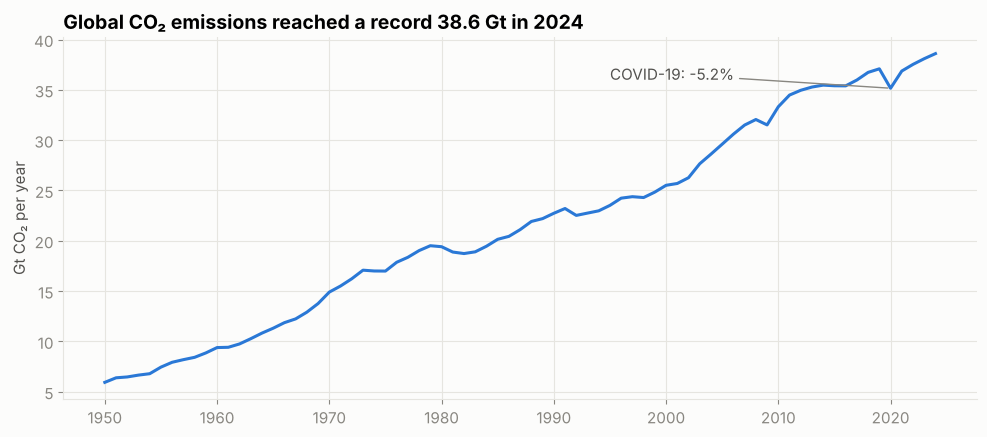

x6.5 since 1950, +70% since 1990


In [3]:
w = world.loc[1950:LAST_YEAR, "co2"] / 1000  # Gt
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(w.index, w.values, color=BLUE, linewidth=2.2)
ax.annotate(f"COVID-19: {(world.co2[2020]/world.co2[2019]-1)*100:.1f}%",
            xy=(2020, world.co2[2020]/1000), xytext=(1995, 36),
            arrowprops=dict(arrowstyle="-", color=MUTED), color="#52514e")
ax.set_title(f"Global CO₂ emissions reached a record {w.iloc[-1]:.1f} Gt in {LAST_YEAR}")
ax.set_ylabel("Gt CO₂ per year")
fig.tight_layout(); fig.savefig(IMG / "global_emissions.png", dpi=150); plt.show()

print(f"x{world.co2[LAST_YEAR]/world.co2[1950]:.1f} since 1950, "
      f"+{(world.co2[LAST_YEAR]/world.co2[1990]-1)*100:.0f}% since 1990")

Emissions have grown more than **6-fold since 1950** and by about **70% since 1990**. The only real drop was in 2020 (COVID-19), followed by an immediate rebound.

## 3. Top emitters today

In [4]:
top = (countries[countries["year"] == LAST_YEAR]
       .nlargest(10, "co2")[["country", "co2", "co2_per_capita", "share_global_co2"]]
       .reset_index(drop=True))
print(f"Top 10 = {top.share_global_co2.sum():.0f}% of global emissions")
top.round(1)

Top 10 = 69% of global emissions


,country,co2,co2_per_capita,share_global_co2
0,China,12289.0,8.7,31.8
1,United States,4904.1,14.2,12.7
2,India,3193.5,2.2,8.3
3,Russia,1780.5,12.3,4.6
4,Japan,961.9,7.8,2.5
5,Indonesia,812.2,2.9,2.1
6,Iran,792.6,8.7,2.1
7,Saudi Arabia,692.1,20.4,1.8
8,South Korea,583.7,11.3,1.5
9,Germany,572.3,6.8,1.5


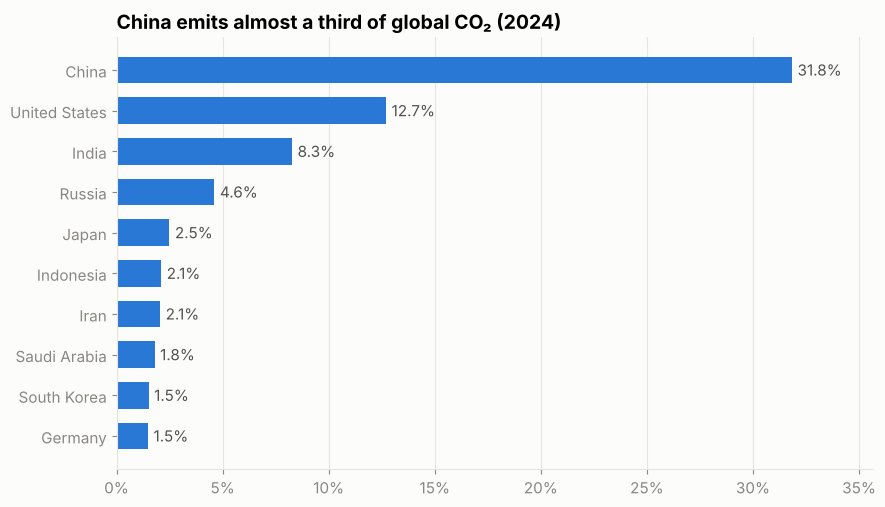

In [5]:
d = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(d["country"], d["share_global_co2"], color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in d["share_global_co2"]], padding=4, color="#52514e")
ax.set_title(f"China emits almost a third of global CO₂ ({LAST_YEAR})")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False); ax.margins(x=0.12)
fig.tight_layout(); fig.savefig(IMG / "top_emitters.png", dpi=150); plt.show()

The 10 largest emitters produce about **69%** of global CO₂. China alone emits **32%**, more than the next three countries combined.

## 4. Total vs per-capita emissions

A large total can hide a low per-person footprint (and vice versa). We compare the top 10 emitters on both metrics.

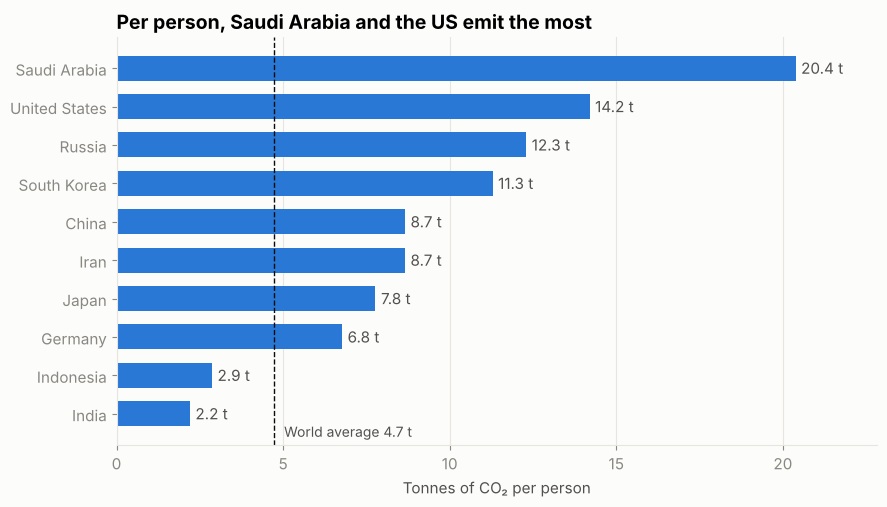

In [6]:
d = top.sort_values("co2_per_capita")
fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(d["country"], d["co2_per_capita"], color=BLUE, height=0.65)
ax.bar_label(bars, labels=[f"{v:.1f} t" for v in d["co2_per_capita"]], padding=4, color="#52514e")
world_pc = world.loc[LAST_YEAR, "co2_per_capita"]
ax.axvline(world_pc, color=INK, linewidth=1, linestyle="--")
ax.text(world_pc + 0.3, -0.6, f"World average {world_pc:.1f} t", color="#52514e", fontsize=10)
ax.set_title("Per person, Saudi Arabia and the US emit the most")
ax.set_xlabel("Tonnes of CO₂ per person")
ax.grid(axis="y", visible=False); ax.margins(x=0.12)
fig.tight_layout(); fig.savefig(IMG / "per_capita_top10.png", dpi=150); plt.show()

India is the 3rd largest emitter but emits only **2.2 t per person**, below the world average (4.7 t). A Saudi resident emits about **9 times more** than an Indian resident.

## 5. Europe, Spain and Tunisia

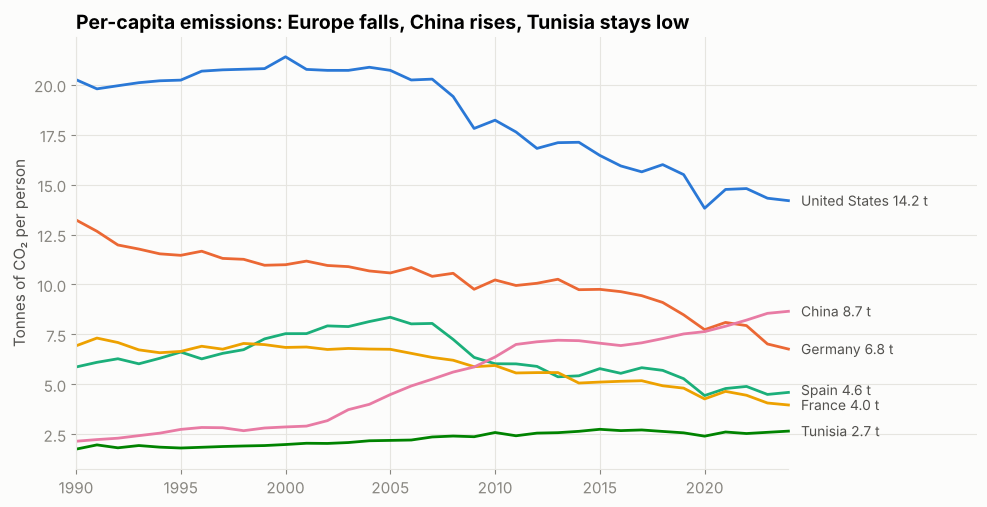

In [7]:
focus = ["United States", "Germany", "Spain", "France", "China", "Tunisia"]
pc = (countries[countries["country"].isin(focus) & countries["year"].between(1990, LAST_YEAR)]
      .pivot(index="year", columns="country", values="co2_per_capita"))[focus]

fig, ax = plt.subplots(figsize=(10, 5.2))
# direct labels at the line ends, nudged apart so they never overlap
ends = pc.iloc[-1].sort_values()
label_y, min_gap = {}, 0.75
for name, y in ends.items():
    prev = max(label_y.values(), default=-99)
    label_y[name] = max(y, prev + min_gap)
for color, name in zip(PALETTE, focus):
    ax.plot(pc.index, pc[name], color=color, linewidth=2)
    ax.text(LAST_YEAR + 0.6, label_y[name], f"{name} {pc[name].iloc[-1]:.1f} t",
            color="#52514e", fontsize=10, va="center")
ax.set_title("Per-capita emissions: Europe falls, China rises, Tunisia stays low")
ax.set_ylabel("Tonnes of CO₂ per person")
ax.set_xlim(1990, LAST_YEAR + 9)
ax.set_xticks(range(1990, LAST_YEAR + 1, 5))
ax.spines["bottom"].set_bounds(1990, LAST_YEAR)
fig.tight_layout(); fig.savefig(IMG / "per_capita_trends.png", dpi=150); plt.show()

In [8]:
change = (countries[countries["year"].isin([1990, 2005, LAST_YEAR])
                   & countries["country"].isin(["Germany", "France", "Spain", "Tunisia", "China"])]
          .pivot(index="country", columns="year", values="co2"))
change["change_since_1990_%"] = (change[LAST_YEAR] / change[1990] - 1) * 100
change.round(1)

year,1990,2005,2024,change_since_1990_%
country,,,,
China,2483.5,5882.0,12289.0,394.8
France,394.9,416.3,264.2,-33.1
Germany,1054.8,867.9,572.3,-45.7
Spain,229.4,367.4,220.3,-3.9
Tunisia,14.6,22.5,32.7,123.4


What stands out:
- **Germany (-46%)** and **France (-33%)** have strongly reduced their emissions since 1990.
- **Spain** rose sharply until its peak in **2005**, then fell back; it is now roughly at its **1990 level**.
- **Tunisia** has more than doubled its emissions, but still emits only **2.7 t per person**, about 40% below the world average.
- **China**'s per-capita emissions have quadrupled since 1990 and now exceed those of Germany and France.

## 6. Emissions by fuel

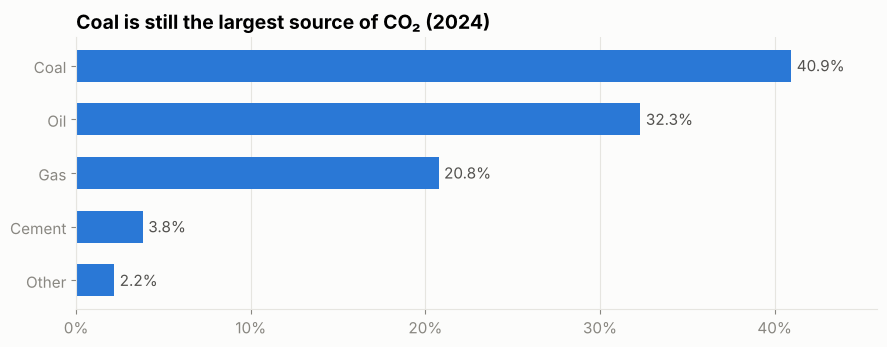

In [9]:
fuels = {"Coal": "coal_co2", "Oil": "oil_co2", "Gas": "gas_co2", "Cement": "cement_co2",
         "Other": ["flaring_co2", "other_industry_co2"]}
share = {k: (world.loc[LAST_YEAR, v].sum() if isinstance(v, list) else world.loc[LAST_YEAR, v])
         / world.loc[LAST_YEAR, "co2"] * 100 for k, v in fuels.items()}
s = pd.Series(share).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(s.index, s.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in s.values], padding=4, color="#52514e")
ax.set_title(f"Coal is still the largest source of CO₂ ({LAST_YEAR})")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False); ax.margins(x=0.12)
fig.tight_layout(); fig.savefig(IMG / "fuel_mix.png", dpi=150); plt.show()

Coal (41%) and oil (32%) account for almost **three quarters** of emissions. Phasing out coal remains the biggest lever.

## 7. Conclusions

1. Global emissions are **still rising** and hit a new record in 2024.
2. Emissions are **highly concentrated**: 10 countries produce ~69%, China alone 32%.
3. **Total and per-capita views tell different stories**: fair comparisons need both.
4. **Europe shows that reductions are possible** (Germany -46%, France -33% since 1990), while emerging economies keep growing.
5. **Coal** is the main source, so energy transition policy should target it first.

Limits: territorial emissions only (imports are not counted), CO₂ only (no methane), and the latest year may be revised by the source.

Next, I would like to publish an interactive version of these charts on Tableau Public.